# Round Win Probability — Training Notebook (de_dust2)

Trains all six model families on the preprocessed dust2 dataset:

| # | Model | Family | Input |
|---|-------|--------|-------|
| 1 | LightGBM | Vector baseline | `df` rows |
| 2 | DeepSets | Set | `X` entries (N×32) |
| 3 | SetTransformer | Set | `X` entries (N×32) |
| 4 | GCN (NNConv) | Graph | `GNN` entries |
| 5 | GAT | Graph | `GNN` entries |
| 6 | Temporal GNN | Graph+sequence | `GNN` sequences per round |

**Evaluation**: Log Loss + ECE (10 bins) on chronological test split.  
**Split**: train Jan–Sep 2025 / val Oct–Nov 2025 / test Dec 2025 (StarLadder Budapest Major).

## 0. Imports & Config

In [2]:
!pip install torch_geometric

In [3]:
import os, json, random, time, warnings
from pathlib import Path
from copy import deepcopy

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam
from torch_geometric.data import Data, Batch
from torch_geometric.loader import DataLoader as PyGLoader
from torch_geometric.nn import NNConv, GATConv, global_mean_pool, BatchNorm
import lightgbm as lgb
from sklearn.metrics import log_loss

warnings.filterwarnings('ignore')
from google.colab import drive
drive.mount('/content/drive')

BASE          = Path('/content/drive/MyDrive/magisterka')
PROCESSED_DIR = BASE / 'data' / 'dust2'
CHECKPOINT_DIR = BASE / 'checkpoints' / 'dust2'
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

# Season sub-directories
S1_DIR = PROCESSED_DIR / 'season1'
S2_DIR = PROCESSED_DIR / 'season2'

print('Processed dir:', PROCESSED_DIR)
print('  Season 1 exists:', S1_DIR.exists())
print('  Season 2 exists:', S2_DIR.exists())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Processed dir: /content/drive/MyDrive/magisterka/data/dust2
  Season 1 exists: True
  Season 2 exists: True


In [4]:

import sys
BASE = Path('/content/drive/MyDrive/magisterka')
sys.path.insert(0, str(BASE))

from dataset import (
    load_processed_matches, chronological_split, flatten_to_states,
    VectorDataset, SetDataset, SetNormaliser,
    GraphDataset, TemporalGraphDataset, temporal_collate_fn,
    build_datasets,
)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

# ── hyper-parameters (following ESTA paper) ────────────────────────────────
# CFG = dict(
#     hidden       = 128,
#     batch_size   = 32,
#     # lr           = 1e-3,
#     lr           = 5e-4,
#     # weight_decay = 1e-5,
#     epochs       = 100,
#     patience     = 10,
#     ece_bins     = 10,
#     # max_seq_len  = 60,
#     max_seq_len  = 120, # for Temporal GNN
#     # chronological split boundaries
# )

CFG = dict(
    hidden       = 128,
    batch_size   = 32,
    lr           = 1e-3,       # back to original
    weight_decay = 1e-4,       # restore this — you removed it
    grad_clip    = 1.0,
    epochs       = 100,
    patience     = 10,
    ece_bins     = 10,
    max_seq_len  = 120,        # keep the increase
)

Device: cuda


## 1. Data Loading & Splitting

In [5]:
# ── Step 1: discover what tournaments exist in Season 2 ───────────────────
# Reads the tournament field from each match's JSON key metadata.
# (Season 1 is automatically training — no need to inspect it.)
from tqdm import tqdm
def get_tournament(match_key: str, match_val: dict) -> str:
    """
    Extract tournament name from the first df entry in the match dict.
    preprocess.py does not store tournament in the JSON body, so we
    reconstruct it from the match_key which has the form:
      TournamentName_team1-vs-team2-m1-mapname
    Everything before the first '_team' segment is the tournament name.
    """
    # The key format is   <TournamentFolder>_<matchfolder>
    # where matchfolder starts with the team names, e.g. 'faze-vs-g2-m1-dust2'
    # Split on the first occurrence of a segment that looks like a team slug.
    # Robust heuristic: the tournament part has no '-vs-' in it.
    parts = match_key.split('_')
    # Walk from the right until we find the part containing '-vs-'
    for i in range(len(parts) - 1, 0, -1):
        if '-vs-' in parts[i]:
            return '_'.join(parts[:i])
    return parts[0]  # fallback


def load_season(season_dir: Path) -> dict:
    """Load all JSON match files from a season directory."""
    data = {}
    if not season_dir.exists():
        return data
    for fname in tqdm(sorted(season_dir.glob('*.json'))):
        with open(fname) as f:
            data.update(json.load(f))
    return data


print('Loading Season 1...')
s1_data = load_season(S1_DIR)
print(f'  Season 1 matches: {len(s1_data)}')

print('Loading Season 2...')
s2_data = load_season(S2_DIR)
print(f'  Season 2 matches: {len(s2_data)}')

# List unique Season 2 tournaments so you can assign them below
s2_tournaments = sorted({get_tournament(k, v) for k, v in s2_data.items()})
print('\nSeason 2 tournaments found:')
for t in s2_tournaments:
    n = sum(1 for k in s2_data if get_tournament(k, s2_data[k]) == t)
    print(f'  {n:3d} matches  |  {t}')

Loading Season 1...


100%|██████████| 237/237 [02:25<00:00,  1.63it/s]


  Season 1 matches: 237
Loading Season 2...


100%|██████████| 167/167 [01:50<00:00,  1.51it/s]

  Season 2 matches: 167

Season 2 tournaments found:
   12 matches  |  BLAST Bounty Season 2
    1 matches  |  BLAST Bounty Season 2 Finals
    9 matches  |  BLAST Open London
    2 matches  |  BLAST Open London Finals
    2 matches  |  BLAST Rivals Season 2
    1 matches  |  BLAST Rivals Season 2 Playoffs
    9 matches  |  CS Asia Championships
    6 matches  |  CS Asia Championships Playoffs
    2 matches  |  ESL Pro League Playoffs
   11 matches  |  ESL Pro League Stage 1
   12 matches  |  ESL Pro League Stage 2
    4 matches  |  Esports World Cup
   17 matches  |  FISSURE Playground 2
    3 matches  |  FISSURE Playground 2 Playoffs
    8 matches  |  IEM Chengdu
    8 matches  |  IEM Cologne
    7 matches  |  IEM Cologne Stage 1
    9 matches  |  PGL Masters Bucharest
    5 matches  |  PGL Masters Bucharest Playoffs
    4 matches  |  StarLadder Major Playoffs
    8 matches  |  StarLadder Major Stage 1
    8 matches  |  StarLadder Major Stage 2
   11 matches  |  StarLadder Major Stag

In [6]:
# ── Step 2: assign Season 2 tournaments to train / val / test ─────────────
#
# Fill this dict after inspecting the list printed above.
# Keys must match EXACTLY the strings printed in the previous cell.
# Values: 'train', 'val', or 'test'.
#
# Chronological convention from the paper (article.pdf):
#   train → up to and including BLAST Rivals Season 1
#   val   → PGL Astana
#   test  → IEM Dallas + BLAST.tv Austin Major
#
# ⚠️  Edit this dict to match YOUR actual tournament folder names.

TOURNAMENT_SPLIT = {
    "StarLadder StarSeries Fall": "train",
    "BLAST Bounty Season 2": "train",
    "BLAST Bounty Season 2 Finals": "train",
    "BLAST Open London": "train",
    "BLAST Open London Finals": "train",
    "Esports World Cup": "train",
    "FISSURE Playground 2": "train",
    "FISSURE Playground 2 Playoffs": "train",
    "IEM Cologne": "train",
    "IEM Cologne Stage 1": "train",


    "ESL Pro League Stage 1": "train",
    "ESL Pro League Stage 2": "val",
    "ESL Pro League Playoffs": "val",


    "CS Asia Championships": "val",
    "CS Asia Championships Playoffs": "val",
    "IEM Chengdu": "val",
    "PGL Masters Bucharest": "val",
    "PGL Masters Bucharest Playoffs": "val",
    "Thunderpick World Championship": "val",
    "BLAST Rivals Season 2": "val",
    "BLAST Rivals Season 2 Playoffs": "val",

    "StarLadder Major Playoffs": "test",
    "StarLadder Major Stage 1": "test",
    "StarLadder Major Stage 2": "test",
    "StarLadder Major Stage 3": "test",

}

# ── Step 3: build train / val / test dicts ────────────────────────────────

train_data = dict(s1_data)   # all Season 1 → train
val_data   = {}
test_data  = {}

unassigned = []
for key, match in s2_data.items():
    tournament = get_tournament(key, match)
    split = TOURNAMENT_SPLIT.get(tournament)
    if split == 'train':
        train_data[key] = match
    elif split == 'val':
        val_data[key] = match
    elif split == 'test':
        test_data[key] = match
    else:
        unassigned.append((tournament, key))

if unassigned:
    print(f'⚠️  {len(unassigned)} Season 2 matches not assigned '
          f'(add their tournaments to TOURNAMENT_SPLIT):')
    for t, k in unassigned[:10]:
        print(f'    {t}  |  {k}')
    if len(unassigned) > 10:
        print(f'    ... and {len(unassigned)-10} more')

# ── Summary ───────────────────────────────────────────────────────────────
def count_states(d): return sum(len(v['Y']) for v in d.values())

def count_rounds(d): return sum(
    len({row.get('roundNum') for row in v['df']})
    for v in d.values()
)

print('\n=== Split Summary ===')
print(f'  Train : {len(train_data):4d} matches  |  {count_rounds(train_data):>8,} rounds  |  {count_states(train_data):>10,} game states')
print(f'  Val   : {len(val_data):4d} matches  |  {count_rounds(val_data):>8,} rounds  |  {count_states(val_data):>10,} game states')
print(f'  Test  : {len(test_data):4d} matches  |  {count_rounds(test_data):>8,} rounds  |  {count_states(test_data):>10,} game states')
# Per-tournament breakdown for the thesis table
print('\n=== Val tournaments ===')
for t in sorted({get_tournament(k, v) for k, v in val_data.items()}):
    n = sum(1 for k in val_data if get_tournament(k, val_data[k]) == t)
    print(f'  {n:3d} matches  |  {t}')

print('\n=== Test tournaments ===')
for t in sorted({get_tournament(k, v) for k, v in test_data.items()}):
    n = sum(1 for k in test_data if get_tournament(k, test_data[k]) == t)
    print(f'  {n:3d} matches  |  {t}')


=== Split Summary ===
  Train :  313 matches  |     6,724 rounds  |     767,541 game states
  Val   :   60 matches  |     1,286 rounds  |     144,808 game states
  Test  :   31 matches  |       703 rounds  |      81,544 game states

=== Val tournaments ===
    2 matches  |  BLAST Rivals Season 2
    1 matches  |  BLAST Rivals Season 2 Playoffs
    9 matches  |  CS Asia Championships
    6 matches  |  CS Asia Championships Playoffs
    2 matches  |  ESL Pro League Playoffs
   12 matches  |  ESL Pro League Stage 2
    8 matches  |  IEM Chengdu
    9 matches  |  PGL Masters Bucharest
    5 matches  |  PGL Masters Bucharest Playoffs
    6 matches  |  Thunderpick World Championship

=== Test tournaments ===
    4 matches  |  StarLadder Major Playoffs
    8 matches  |  StarLadder Major Stage 1
    8 matches  |  StarLadder Major Stage 2
   11 matches  |  StarLadder Major Stage 3


In [ ]:
datasets = build_datasets(
    train_data, val_data, test_data,
    temporal=False,
    max_seq_len=CFG['max_seq_len'],
)
print('Datasets ready.')

# Save normaliser so it can be reloaded for inference later
datasets['set']['normaliser'].save(str(CHECKPOINT_DIR / 'normaliser'))
print(f'Normaliser saved to {CHECKPOINT_DIR / "normaliser.npz"}')

In [7]:
from dataset import TemporalGraphDataset, temporal_collate_fn

temporal_train = TemporalGraphDataset(train_data, max_len=120)  # compromise: 80 not 120
temporal_val   = TemporalGraphDataset(val_data,   max_len=120)
temporal_test  = TemporalGraphDataset(test_data,  max_len=120)

## 2. Evaluation Utilities

In [8]:
def compute_ece(y_true: np.ndarray, y_prob: np.ndarray, n_bins: int = 10) -> float:
    """Expected Calibration Error (equal-width bins, Equation 1 in ESTA)."""
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece  = 0.0
    n    = len(y_true)
    for lo, hi in zip(bins[:-1], bins[1:]):
        mask = (y_prob >= lo) & (y_prob < hi)
        if mask.sum() == 0:
            continue
        acc  = y_true[mask].mean()
        conf = y_prob[mask].mean()
        ece += mask.sum() / n * abs(acc - conf)
    return float(ece)


def evaluate_numpy(y_true: np.ndarray, y_prob: np.ndarray,
                   label: str = '') -> dict:
    """Compute Log Loss and ECE from numpy arrays."""
    ll  = log_loss(y_true, y_prob)
    ece = compute_ece(y_true, y_prob, CFG['ece_bins'])
    print(f'  [{label}] Log Loss: {ll:.4f}  |  ECE: {ece:.4f}')
    return {'log_loss': ll, 'ece': ece}


@torch.no_grad()
def predict_set_model(model, batches) -> tuple:
    """Run inference on batches from SetDataset.make_batches()."""
    model.eval()
    all_prob, all_true = [], []
    for xb, yb in batches:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        logits = model(xb)
        all_prob.append(torch.sigmoid(logits).cpu().numpy().flatten())
        all_true.append(yb.cpu().numpy().flatten())
    return np.concatenate(all_true), np.concatenate(all_prob)


@torch.no_grad()
def predict_graph_model(model, loader) -> tuple:
    """Run inference on a PyG DataLoader."""
    model.eval()
    all_prob, all_true = [], []
    for batch in loader:
        batch = batch.to(DEVICE)
        logits = model(batch)
        all_prob.append(torch.sigmoid(logits).cpu().numpy().flatten())
        all_true.append(batch.y.cpu().numpy().flatten())
    return np.concatenate(all_true), np.concatenate(all_prob)


def results_table(results: dict) -> pd.DataFrame:
    rows = []
    for model_name, splits in results.items():
        for split_name, metrics in splits.items():
            rows.append({'model': model_name, 'split': split_name, **metrics})
    return pd.DataFrame(rows).set_index(['model', 'split']).round(4)

## 3. Model Definitions

### 3.1 DeepSets

In [18]:
class DeepSets(nn.Module):
    """
    DeepSets (Zaheer et al., 2017).
    Dropout applied in both φ and ρ to regularise against overfitting
    on the highly correlated within-round game states.
    """
    def __init__(self, in_features: int = 32, hidden: int = 64, dropout: float = 0.3):
        super().__init__()
        self.phi = nn.Sequential(
            nn.Linear(in_features, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, hidden),
        )
        self.rho = nn.Sequential(
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        z = self.phi(x).mean(dim=1)
        return self.rho(z)

### 3.2 SetTransformer

In [19]:
class MultiheadAttentionBlock(nn.Module):
    def __init__(self, d_model: int, num_heads: int, dropout: float = 0.1):
        super().__init__()
        self.attn  = nn.MultiheadAttention(d_model, num_heads, batch_first=True, dropout=dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.ff    = nn.Sequential(
            nn.Linear(d_model, d_model), nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(d_model, d_model)
        )
        self.norm2 = nn.LayerNorm(d_model)

    def forward(self, x):
        attn_out, _ = self.attn(x, x, x)
        x = self.norm1(x + attn_out)
        return self.norm2(x + self.ff(x))


class InducedSetAttentionBlock(nn.Module):
    def __init__(self, d_model: int, num_heads: int, num_inds: int = 4, dropout: float = 0.1):
        super().__init__()
        self.I    = nn.Parameter(torch.randn(1, num_inds, d_model))
        self.mab0 = MultiheadAttentionBlock(d_model, num_heads, dropout)
        self.mab1 = MultiheadAttentionBlock(d_model, num_heads, dropout)

    def forward(self, x):
        B = x.size(0)
        H = self.mab0(torch.cat([self.I.expand(B, -1, -1), x], dim=1))[:, :self.I.size(1), :]
        return self.mab1(torch.cat([x, H], dim=1))[:, :x.size(1), :]


class PoolingByMultiheadAttention(nn.Module):
    def __init__(self, d_model: int, num_heads: int, k: int = 1, dropout: float = 0.1):
        super().__init__()
        self.S   = nn.Parameter(torch.randn(1, k, d_model))
        self.mab = MultiheadAttentionBlock(d_model, num_heads, dropout)

    def forward(self, x):
        B = x.size(0)
        return self.mab(torch.cat([self.S.expand(B, -1, -1), x], dim=1))[:, :self.S.size(1), :]


class SetTransformer(nn.Module):
    def __init__(self, in_features: int = 32, hidden: int = 64,
                 num_heads: int = 1, num_inds: int = 4, dropout: float = 0.1):
        super().__init__()
        self.embed   = nn.Linear(in_features, hidden)
        self.encoder = InducedSetAttentionBlock(hidden, num_heads, num_inds, dropout)
        self.decoder = PoolingByMultiheadAttention(hidden, num_heads, k=1, dropout=dropout)
        self.drop    = nn.Dropout(dropout)
        self.head    = nn.Linear(hidden, 1)

    def forward(self, x):
        x = F.relu(self.embed(x))
        x = self.encoder(x)
        x = self.decoder(x).squeeze(1)
        return self.head(self.drop(x))

### 3.3 GCN (NNConv)

In [20]:
def _make_edge_net(num_edge_features, in_ch, out_ch, hidden):
    """Edge MLP for NNConv. Xavier init with small gain prevents dead start."""
    net = nn.Sequential(
        nn.Linear(num_edge_features, hidden),
        nn.ReLU(),
        nn.Linear(hidden, in_ch * out_ch),
    )
    for layer in net:
        if isinstance(layer, nn.Linear):
            nn.init.xavier_uniform_(layer.weight, gain=0.1)
            nn.init.zeros_(layer.bias)
    return net


class GCN(nn.Module):
    """
    NNConv GCN with corrected edge-net initialisation and dropout.
    The small xavier gain (0.1) prevents the edge weight matrices from
    producing exploding/vanishing signals at initialisation, which caused
    the model to predict ~0.5 for all inputs in the first run.
    """
    def __init__(self, hidden: int = 128,
                 num_node_features: int = 32,
                 num_edge_features: int = 3,
                 dropout: float = 0.3):
        super().__init__()
        self.conv1 = NNConv(num_node_features, hidden,
                            _make_edge_net(num_edge_features, num_node_features, hidden, hidden),
                            aggr='mean')
        self.bn1   = BatchNorm(hidden)

        self.conv2 = NNConv(hidden, hidden,
                            _make_edge_net(num_edge_features, hidden, hidden, hidden),
                            aggr='mean')
        self.bn2   = BatchNorm(hidden)

        self.mlp = nn.Sequential(
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, data):
        x, ei, ea, batch = data.x, data.edge_index, data.edge_attr, data.batch
        x = F.relu(self.bn1(self.conv1(x, ei, ea)))
        x = F.relu(self.bn2(self.conv2(x, ei, ea)))
        x = global_mean_pool(x, batch)
        return self.mlp(x)

### 3.4 GAT

In [21]:
from torch_geometric.utils import dropout_edge
class GAT(nn.Module):
    def __init__(self, hidden: int = 128,
                 num_node_features: int = 32,
                 num_edge_features: int = 3,
                 heads: int = 4,
                 dropout: float = 0.3):
        super().__init__()
        head_dim = hidden // heads
        self.conv1 = GATConv(num_node_features, head_dim, heads=heads,
                             edge_dim=num_edge_features, concat=True, dropout=dropout)
        self.bn1   = BatchNorm(hidden)
        self.conv2 = GATConv(hidden, head_dim, heads=heads,
                             edge_dim=num_edge_features, concat=True, dropout=dropout)
        self.bn2   = BatchNorm(hidden)
        self.mlp = nn.Sequential(
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, data):
        x, ei, ea, batch = data.x, data.edge_index, data.edge_attr, data.batch

        # Drop edges during training only
        if self.training:
            ei, edge_mask = dropout_edge(ei, p=0.3, training=True)
            ea = ea[edge_mask]
        x = F.relu(self.bn1(self.conv1(x, ei, ea)))
        x = F.relu(self.bn2(self.conv2(x, ei, ea)))
        x = global_mean_pool(x, batch)
        return self.mlp(x)

### 3.5 Temporal GNN (GRU over NNConv graphs)

In [9]:
class TemporalGNN(nn.Module):
    """
    Spatio-temporal model: NNConv graph encoder + GRU sequence model.

    For each game state in a round sequence, the GNN encoder produces a
    fixed-size graph embedding via global mean pooling.  These embeddings
    are fed as a time series into a single-layer GRU.  The final hidden
    state is projected to a scalar win-probability logit.

    Input : list of PyG Batch objects (one per time step) + masks + labels
            (from temporal_collate_fn in dataset.py)
    Output: (B, 1) logit
    """

    def __init__(self, hidden: int = 128,
                 num_node_features: int = 32,
                 num_edge_features: int = 3,
                 gru_layers: int = 1):
        super().__init__()

        # Graph encoder (shared across time steps)
        nn1 = nn.Sequential(
            nn.Linear(num_edge_features, hidden),
            nn.ReLU(),
            nn.Linear(hidden, num_node_features * hidden),
        )
        self.conv1 = NNConv(num_node_features, hidden, nn1, aggr='mean')
        self.bn1   = BatchNorm(hidden)

        nn2 = nn.Sequential(
            nn.Linear(num_edge_features, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden * hidden),
        )
        self.conv2 = NNConv(hidden, hidden, nn2, aggr='mean')
        self.bn2   = BatchNorm(hidden)

        # Temporal model
        self.gru   = nn.GRU(hidden, hidden, num_layers=gru_layers,
                            batch_first=True)
        self.head  = nn.Linear(hidden, 1)

    def encode_graph(self, data) -> torch.Tensor:
        """Encode a single-timestep batched graph → (num_graphs, hidden)."""
        x, ei, ea, batch = data.x, data.edge_index, data.edge_attr, data.batch
        x = F.relu(self.bn1(self.conv1(x, ei, ea)))
        x = F.relu(self.bn2(self.conv2(x, ei, ea)))
        return global_mean_pool(x, batch)   # (G, H)

    def forward(self, timestep_batches, masks, batch_size: int) -> torch.Tensor:
        """
        Args:
          timestep_batches : list[PyG Batch or None], length = max_T
          masks            : list[list[bool]], shape (max_T, B)
          batch_size       : B (total sequences in this batch)
        Returns:
          (B, 1) logit
        """
        H = self.gru.hidden_size
        T = len(timestep_batches)

        # Build (B, T, H) embedding tensor
        seq = torch.zeros(batch_size, T, H, device=next(self.parameters()).device)

        # Track position within the sub-batch at each time step
        batch_ptr = [0] * T   # pointer into graph-level outputs at step t
        graph_embs = []
        for t, g_batch in enumerate(timestep_batches):
            if g_batch is not None:
                g_batch = g_batch.to(next(self.parameters()).device)
                emb = self.encode_graph(g_batch)   # (num_present, H)
                graph_embs.append(emb)
            else:
                graph_embs.append(None)

        ptr = {t: 0 for t in range(T)}
        for b in range(batch_size):
            for t in range(T):
                if masks[t][b] and graph_embs[t] is not None:
                    seq[b, t] = graph_embs[t][ptr[t]]
                    ptr[t] += 1
                # else: zero-padding (sequence shorter than max_T)

        _, h_n = self.gru(seq)          # h_n: (layers, B, H)
        return self.head(h_n[-1])       # (B, 1)

### 3.6 GCN Fix

In [33]:
from torch_geometric.nn import GCNConv

class GCNSimple(nn.Module):
    """
    Two-layer GCN with scalar edge weights.

    Edge features [inv_geodesic_dist, visibility, same_team] are handled
    as follows:
      - inv_geodesic_dist → scalar edge weight passed to GCNConv
      - visibility + same_team → concatenated to each node's feature
        vector before the first convolution (node augmentation trick)

    This avoids the NNConv ill-conditioning problem while preserving
    all three edge signals.

    Input node features : 32-dim  →  augmented to 32+2=34-dim
    """

    def __init__(self, hidden: int = 128,
                 num_node_features: int = 32,
                 num_edge_features: int = 3,
                 dropout: float = 0.3):
        super().__init__()
        # visibility + same_team appended → input dim increases by 2
        augmented_dim = num_node_features + 2

        self.conv1 = GCNConv(augmented_dim, hidden)
        self.bn1   = BatchNorm(hidden)
        self.conv2 = GCNConv(hidden, hidden)
        self.bn2   = BatchNorm(hidden)

        self.mlp = nn.Sequential(
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, data):
        x, ei, ea, batch = data.x, data.edge_index, data.edge_attr, data.batch

        if self.training:
            ei, edge_mask = dropout_edge(ei, p=0.5, training=True)
            ea = ea[edge_mask]

        n = x.size(0)
        src = ei[0]
        vis_agg  = torch.zeros(n, 1, device=x.device)
        team_agg = torch.zeros(n, 1, device=x.device)
        count    = torch.zeros(n, 1, device=x.device)
        vis_agg.scatter_add_(0, src.unsqueeze(1), ea[:, 1].unsqueeze(1))
        team_agg.scatter_add_(0, src.unsqueeze(1), ea[:, 2].unsqueeze(1))
        count.scatter_add_(0, src.unsqueeze(1), torch.ones(src.size(0), 1, device=x.device))
        count = count.clamp(min=1)

        x_aug = torch.cat([x, vis_agg / count, team_agg / count], dim=1)
        edge_weight = ea[:, 0].clamp(max=10.0)

        x_aug = F.relu(self.bn1(self.conv1(x_aug, ei, edge_weight)))
        x_aug = F.relu(self.bn2(self.conv2(x_aug, ei, edge_weight)))
        return self.mlp(global_mean_pool(x_aug, batch))

## 4. Training Loop Helpers

In [13]:
# ── shared training config additions ──────────────────────────────────────
CFG['weight_decay'] = 1e-4
CFG['grad_clip']    = 1.0


def train_set_model(model, train_ds, val_ds, name,
                    epochs=CFG['epochs'], batch_size=CFG['batch_size'],
                    patience=CFG['patience']):
    model = model.to(DEVICE)
    optim = Adam(model.parameters(), lr=CFG['lr'], weight_decay=CFG['weight_decay'])
    criterion = nn.BCEWithLogitsLoss()
    ckpt_path = CHECKPOINT_DIR / f'{name}.pt'

    best_val_loss, best_epoch, no_improve = float('inf'), 0, 0

    for epoch in range(1, epochs + 1):
        model.train()
        total_loss, total_n = 0.0, 0
        for xb, yb in train_ds.make_batches(batch_size, shuffle=True):
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optim.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), CFG['grad_clip'])
            optim.step()
            total_loss += loss.item() * xb.size(0)
            total_n    += xb.size(0)

        val_batches = val_ds.make_batches(batch_size, shuffle=False)
        y_true, y_prob = predict_set_model(model, val_batches)
        val_ll = log_loss(y_true, y_prob)
        print(f'  Epoch {epoch:3d} | train LL {total_loss/total_n:.4f} | val LL {val_ll:.4f}')

        if val_ll < best_val_loss:
            best_val_loss, best_epoch, no_improve = val_ll, epoch, 0
            torch.save(model.state_dict(), ckpt_path)
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f'  Early stopping at epoch {epoch} (best epoch {best_epoch})')
                break

    model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
    return model


def train_graph_model(model, train_ds, val_ds, name,
                      epochs=CFG['epochs'], batch_size=CFG['batch_size'],
                      patience=CFG['patience']):
    model = model.to(DEVICE)
    optim = Adam(model.parameters(), lr=CFG['lr'], weight_decay=CFG['weight_decay'])
    criterion = nn.BCEWithLogitsLoss()
    ckpt_path = CHECKPOINT_DIR / f'{name}.pt'

    train_loader = PyGLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader   = PyGLoader(val_ds,   batch_size=batch_size, shuffle=False)

    best_val_loss, best_epoch, no_improve = float('inf'), 0, 0

    for epoch in range(1, epochs + 1):
        model.train()
        total_loss, total_n = 0.0, 0
        for batch in train_loader:
            batch = batch.to(DEVICE)
            optim.zero_grad()
            logits = model(batch)
            loss = criterion(logits, batch.y.float().unsqueeze(1))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), CFG['grad_clip'])
            optim.step()
            total_loss += loss.item() * batch.num_graphs
            total_n    += batch.num_graphs

        y_true, y_prob = predict_graph_model(model, val_loader)
        val_ll = log_loss(y_true, y_prob)
        print(f'  Epoch {epoch:3d} | train LL {total_loss/total_n:.4f} | val LL {val_ll:.4f}')

        if val_ll < best_val_loss:
            best_val_loss, best_epoch, no_improve = val_ll, epoch, 0
            torch.save(model.state_dict(), ckpt_path)
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f'  Early stopping at epoch {epoch} (best epoch {best_epoch})')
                break

    model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
    return model


def train_temporal_gnn(model, train_ds, val_ds, name,
                       epochs=CFG['epochs'], batch_size=CFG['batch_size'],
                       patience=CFG['patience'],lr=CFG['lr']):
    from torch.utils.data import DataLoader
    model = model.to(DEVICE)
    optim = Adam(model.parameters(), lr=lr, weight_decay=CFG['weight_decay'])
    criterion = nn.BCEWithLogitsLoss()
    ckpt_path = CHECKPOINT_DIR / f'{name}.pt'

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                              collate_fn=temporal_collate_fn)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False,
                              collate_fn=temporal_collate_fn)

    best_val_loss, best_epoch, no_improve = float('inf'), 0, 0

    for epoch in range(1, epochs + 1):
        model.train()
        total_loss, total_n = 0.0, 0
        for ts_batches, masks, labels in train_loader:
            labels = labels.float().unsqueeze(1).to(DEVICE)
            optim.zero_grad()
            logits = model(ts_batches, masks, labels.size(0))
            loss = criterion(logits, labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), CFG['grad_clip'])
            optim.step()
            total_loss += loss.item() * labels.size(0)
            total_n    += labels.size(0)

        model.eval()
        val_probs, val_true = [], []
        with torch.no_grad():
            for ts_batches, masks, labels in val_loader:
                lbl = labels.float().unsqueeze(1).to(DEVICE)
                logits = model(ts_batches, masks, lbl.size(0))
                val_probs.append(torch.sigmoid(logits).cpu().numpy().flatten())
                val_true.append(labels.numpy().flatten())
        val_ll = log_loss(np.concatenate(val_true), np.concatenate(val_probs))
        print(f'  Epoch {epoch:3d} | train LL {total_loss/total_n:.4f} | val LL {val_ll:.4f}')

        if val_ll < best_val_loss:
            best_val_loss, best_epoch, no_improve = val_ll, epoch, 0
            torch.save(model.state_dict(), ckpt_path)
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f'  Early stopping at epoch {epoch} (best epoch {best_epoch})')
                break

    model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
    return model

## 5. Train All Models

### 5.1 LightGBM (Vector Baseline)

In [25]:
print('=== LightGBM ===')

X_train, y_train = datasets['vector']['train'].get_features()
X_val,   y_val   = datasets['vector']['val'].get_features()
X_test,  y_test  = datasets['vector']['test'].get_features()

lgb_train = lgb.Dataset(X_train, label=y_train)
lgb_val   = lgb.Dataset(X_val,   label=y_val,   reference=lgb_train)

lgb_params = dict(
    objective        = 'binary',
    metric           = 'binary_logloss',
    num_leaves       = 63,
    learning_rate    = 0.05,
    feature_fraction = 0.9,
    bagging_fraction = 0.8,
    bagging_freq     = 5,
    verbose          = -1,
    seed             = SEED,
)

callbacks = [
    lgb.early_stopping(stopping_rounds=CFG['patience'], verbose=True),
    lgb.log_evaluation(period=20),
]

lgbm_model = lgb.train(
    lgb_params,
    lgb_train,
    num_boost_round=500,
    valid_sets=[lgb_val],
    callbacks=callbacks,
)

lgbm_results = {}
for split, X, y in [('val', X_val, y_val), ('test', X_test, y_test)]:
    prob = lgbm_model.predict(X)
    lgbm_results[split] = evaluate_numpy(y, prob, f'LightGBM/{split}')

lgbm_model.save_model(str(CHECKPOINT_DIR / 'lightgbm.txt'))
print('LightGBM saved.')

=== LightGBM ===
Training until validation scores don't improve for 10 rounds
[20]	valid_0's binary_logloss: 0.516757
[40]	valid_0's binary_logloss: 0.47258
[60]	valid_0's binary_logloss: 0.459063
[80]	valid_0's binary_logloss: 0.453855
[100]	valid_0's binary_logloss: 0.451957
[120]	valid_0's binary_logloss: 0.451867
Early stopping, best iteration is:
[112]	valid_0's binary_logloss: 0.451549
  [LightGBM/val] Log Loss: 0.4515  |  ECE: 0.0288
  [LightGBM/test] Log Loss: 0.4590  |  ECE: 0.0158
LightGBM saved.


### 5.2 DeepSets

In [ ]:
print('=== DeepSets ===')

deepsets_model = train_set_model(
    DeepSets(in_features=32, hidden=CFG['hidden']),
    datasets['set']['train'],
    datasets['set']['val'],
    name='deepsets',
)

deepsets_results = {}
for split, ds in [('val', datasets['set']['val']),
                  ('test', datasets['set']['test'])]:
    batches = ds.make_batches(CFG['batch_size'], shuffle=False)
    y_true, y_prob = predict_set_model(deepsets_model, batches)
    deepsets_results[split] = evaluate_numpy(y_true, y_prob, f'DeepSets/{split}')

=== DeepSets ===
  Epoch   1 | train LL 0.4565 | val LL 0.4610
  Epoch   2 | train LL 0.4488 | val LL 0.4591
  Epoch   3 | train LL 0.4469 | val LL 0.4524
  Epoch   4 | train LL 0.4466 | val LL 0.4603
  Epoch   5 | train LL 0.4461 | val LL 0.4582
  Epoch   6 | train LL 0.4461 | val LL 0.4547
  Epoch   7 | train LL 0.4455 | val LL 0.4614
  Epoch   8 | train LL 0.4450 | val LL 0.4543
  Epoch   9 | train LL 0.4444 | val LL 0.4575
  Epoch  10 | train LL 0.4443 | val LL 0.4623
  Epoch  11 | train LL 0.4438 | val LL 0.4593
  Epoch  12 | train LL 0.4431 | val LL 0.4544
  Epoch  13 | train LL 0.4431 | val LL 0.4601
  Early stopping at epoch 13 (best epoch 3)
  [DeepSets/val] Log Loss: 0.4524  |  ECE: 0.0278
  [DeepSets/test] Log Loss: 0.4691  |  ECE: 0.0660


### 5.3 SetTransformer

In [ ]:
print('=== SetTransformer ===')

settransformer_model = train_set_model(
    SetTransformer(in_features=32, hidden=CFG['hidden'], num_heads=1),
    datasets['set']['train'],
    datasets['set']['val'],
    name='settransformer',
)

settransformer_results = {}
for split, ds in [('val', datasets['set']['val']),
                  ('test', datasets['set']['test'])]:
    batches = ds.make_batches(CFG['batch_size'], shuffle=False)
    y_true, y_prob = predict_set_model(settransformer_model, batches)
    settransformer_results[split] = evaluate_numpy(
        y_true, y_prob, f'SetTransformer/{split}')

=== SetTransformer ===
  Epoch   1 | train LL 0.4483 | val LL 0.4801
  Epoch   2 | train LL 0.4213 | val LL 0.5028
  Epoch   3 | train LL 0.4035 | val LL 0.5164
  Epoch   4 | train LL 0.3889 | val LL 0.5442
  Epoch   5 | train LL 0.3743 | val LL 0.5615
  Epoch   6 | train LL 0.3641 | val LL 0.5413
  Epoch   7 | train LL 0.3555 | val LL 0.5933
  Epoch   8 | train LL 0.3477 | val LL 0.5973
  Epoch   9 | train LL 0.3420 | val LL 0.6183
  Epoch  10 | train LL 0.3365 | val LL 0.5831
  Epoch  11 | train LL 0.3307 | val LL 0.5951
  Early stopping at epoch 11 (best epoch 1)
  [SetTransformer/val] Log Loss: 0.4801  |  ECE: 0.0670
  [SetTransformer/test] Log Loss: 0.4672  |  ECE: 0.0314


### 5.4 GCN

In [26]:
print('=== GCN ===')

gcn_model = train_graph_model(
    GCN(hidden=CFG['hidden']),
    datasets['graph']['train'],
    datasets['graph']['val'],
    name='gcn',
)

gcn_results = {}
for split, ds in [('val', datasets['graph']['val']),
                  ('test', datasets['graph']['test'])]:
    loader = PyGLoader(ds, batch_size=CFG['batch_size'], shuffle=False)
    y_true, y_prob = predict_graph_model(gcn_model, loader)
    gcn_results[split] = evaluate_numpy(y_true, y_prob, f'GCN/{split}')

=== GCN ===


KeyboardInterrupt: 

### 5.5 GAT

In [ ]:
print('=== GAT ===')

gat_model = train_graph_model(
    GAT(hidden=CFG['hidden'], heads=4),
    datasets['graph']['train'],
    datasets['graph']['val'],
    name='gat',
)

gat_results = {}
for split, ds in [('val', datasets['graph']['val']),
                  ('test', datasets['graph']['test'])]:
    loader = PyGLoader(ds, batch_size=CFG['batch_size'], shuffle=False)
    y_true, y_prob = predict_graph_model(gat_model, loader)
    gat_results[split] = evaluate_numpy(y_true, y_prob, f'GAT/{split}')

### 5.6 Temporal GNN

In [14]:
print('=== Temporal GNN ===')

temporal_model = train_temporal_gnn(
    TemporalGNN(hidden=128),
    # datasets['temporal']['train'],
    temporal_train,
    temporal_val,
    # datasets['temporal']['val'],
    name='temporal_gnn_v2',
    lr=5e-4
)

from torch.utils.data import DataLoader

temporal_results = {}
temporal_model.eval()
for split, ds in [('val', datasets['temporal']['val']),
                  ('test', datasets['temporal']['test'])]:
    loader = DataLoader(ds, batch_size=CFG['batch_size'],
                        shuffle=False, collate_fn=temporal_collate_fn)
    all_prob, all_true = [], []
    with torch.no_grad():
        for ts_batches, masks, labels in loader:
            lbl = labels.float().unsqueeze(1).to(DEVICE)
            logits = temporal_model(ts_batches, masks, lbl.size(0))
            all_prob.append(torch.sigmoid(logits).cpu().numpy().flatten())
            all_true.append(labels.numpy().flatten())
    y_true = np.concatenate(all_true)
    y_prob = np.concatenate(all_prob)
    temporal_results[split] = evaluate_numpy(y_true, y_prob,
                                              f'TemporalGNN/{split}')

=== Temporal GNN ===
  Epoch   1 | train LL 0.6298 | val LL 0.7578
  Epoch   2 | train LL 0.5559 | val LL 0.6473
  Epoch   3 | train LL 0.5489 | val LL 0.6374
  Epoch   4 | train LL 0.5391 | val LL 0.6444
  Epoch   5 | train LL 0.5404 | val LL 0.7520
  Epoch   6 | train LL 0.5260 | val LL 0.6265
  Epoch   7 | train LL 0.5360 | val LL 0.7432
  Epoch   8 | train LL 0.5167 | val LL 0.6657
  Epoch   9 | train LL 0.5201 | val LL 0.6502
  Epoch  10 | train LL 0.5114 | val LL 0.6688
  Epoch  11 | train LL 0.5136 | val LL 0.6387
  Epoch  12 | train LL 0.5201 | val LL 0.7579
  Epoch  13 | train LL 0.5144 | val LL 0.6330
  Epoch  14 | train LL 0.5052 | val LL 1.0689
  Epoch  15 | train LL 0.5083 | val LL 0.7141
  Epoch  16 | train LL 0.5142 | val LL 0.6871
  Early stopping at epoch 16 (best epoch 6)


NameError: name 'datasets' is not defined

In [15]:
for split, ds in [('val', temporal_val),
                  ('test', temporal_test)]:
    loader = DataLoader(ds, batch_size=CFG['batch_size'],
                        shuffle=False, collate_fn=temporal_collate_fn)
    all_prob, all_true = [], []
    with torch.no_grad():
        for ts_batches, masks, labels in loader:
            lbl = labels.float().unsqueeze(1).to(DEVICE)
            logits = temporal_model(ts_batches, masks, lbl.size(0))
            all_prob.append(torch.sigmoid(logits).cpu().numpy().flatten())
            all_true.append(labels.numpy().flatten())
    y_true = np.concatenate(all_true)
    y_prob = np.concatenate(all_prob)
    temporal_results[split] = evaluate_numpy(y_true, y_prob,
                                              f'TemporalGNN/{split}')

  [TemporalGNN/val] Log Loss: 0.6265  |  ECE: 0.0247
  [TemporalGNN/test] Log Loss: 0.6342  |  ECE: 0.0415


### 5.6 GCN Simple

In [34]:
# ── Train GCNSimple ────────────────────────────────────────────────────────
print('=== GCNSimple ===')

gcn_simple_model = train_graph_model(
    GCNSimple(hidden=64, dropout=0.3),
    datasets['graph']['train'],
    datasets['graph']['val'],
    name='gcn_simple',
)

gcn_simple_results = {}
for split, ds in [('val',  datasets['graph']['val']),
                  ('test', datasets['graph']['test'])]:
    loader = PyGLoader(ds, batch_size=CFG['batch_size'], shuffle=False)
    y_true, y_prob = predict_graph_model(gcn_simple_model, loader)
    gcn_simple_results[split] = evaluate_numpy(y_true, y_prob, f'GCNSimple/{split}')

=== GCNSimple ===
  Epoch   1 | train LL 0.4494 | val LL 0.4570
  Epoch   2 | train LL 0.4380 | val LL 0.4566
  Epoch   3 | train LL 0.4327 | val LL 0.4678
  Epoch   4 | train LL 0.4284 | val LL 0.4665
  Epoch   5 | train LL 0.4245 | val LL 0.4774
  Epoch   6 | train LL 0.4206 | val LL 0.4889
  Epoch   7 | train LL 0.4176 | val LL 0.4793
  Epoch   8 | train LL 0.4145 | val LL 0.4819
  Epoch   9 | train LL 0.4123 | val LL 0.4908
  Epoch  10 | train LL 0.4100 | val LL 0.4961
  Epoch  11 | train LL 0.4077 | val LL 0.4907
  Epoch  12 | train LL 0.4058 | val LL 0.5027
  Early stopping at epoch 12 (best epoch 2)
  [GCNSimple/val] Log Loss: 0.4566  |  ECE: 0.0275
  [GCNSimple/test] Log Loss: 0.4603  |  ECE: 0.0266


## 6. Results Summary

In [39]:
# ── Load all saved checkpoints ─────────────────────────────────────────────
# Run this after reloading data and redefining all model classes.
import lightgbm as lgb

lgbm_model = lgb.Booster(model_file=str(CHECKPOINT_DIR / 'lightgbm.txt'))
X_test, y_test = datasets['vector']['test'].get_features()

deepsets_model = DeepSets(in_features=32, hidden=128, dropout=0.3).to(DEVICE)
deepsets_model.load_state_dict(torch.load(CHECKPOINT_DIR / 'deepsets.pt', map_location=DEVICE))
deepsets_model.eval()

settransformer_model = SetTransformer(in_features=32, hidden=128, num_heads=1, dropout=0.1).to(DEVICE)
settransformer_model.load_state_dict(torch.load(CHECKPOINT_DIR / 'settransformer.pt', map_location=DEVICE))
settransformer_model.eval()

gcn_model = GCN(hidden=128, dropout=0.3).to(DEVICE)
gcn_model.load_state_dict(torch.load(CHECKPOINT_DIR / 'gcn.pt', map_location=DEVICE))
gcn_model.eval()

gat_model = GAT(hidden=128, heads=4, dropout=0.3).to(DEVICE)
gat_model.load_state_dict(torch.load(CHECKPOINT_DIR / 'gat.pt', map_location=DEVICE))
gat_model.eval()

temporal_model = TemporalGNN(hidden=128).to(DEVICE)
temporal_model.load_state_dict(torch.load(CHECKPOINT_DIR / 'temporal_gnn.pt', map_location=DEVICE))
temporal_model.eval()

print('All checkpoints loaded.')

All checkpoints loaded.


In [40]:
# ── Collect test predictions for all models ────────────────────────────────
from torch.utils.data import DataLoader as TorchDataLoader

test_preds = {}  # model_name -> (y_true, y_prob)

# LightGBM
yt = y_test.values if hasattr(y_test, 'values') else np.array(y_test)
test_preds['LightGBM'] = (yt, lgbm_model.predict(X_test))

# Set models
for name, model in [('DeepSets', deepsets_model), ('SetTransformer', settransformer_model)]:
    batches = datasets['set']['test'].make_batches(CFG['batch_size'], shuffle=False)
    test_preds[name] = predict_set_model(model, batches)

# Graph models
for name, model in [('GCN', gcn_model), ('GAT', gat_model)]:
    loader = PyGLoader(datasets['graph']['test'], batch_size=CFG['batch_size'], shuffle=False)
    test_preds[name] = predict_graph_model(model, loader)

# Temporal GNN
loader = TorchDataLoader(datasets['temporal']['test'], batch_size=CFG['batch_size'],
                         shuffle=False, collate_fn=temporal_collate_fn)
all_p, all_t = [], []
with torch.no_grad():
    for ts_batches, masks, labels in loader:
        lbl = labels.float().unsqueeze(1).to(DEVICE)
        logits = temporal_model(ts_batches, masks, lbl.size(0))
        all_p.append(torch.sigmoid(logits).cpu().numpy().flatten())
        all_t.append(labels.numpy().flatten())
test_preds['TemporalGNN'] = (np.concatenate(all_t), np.concatenate(all_p))

# In the predictions collection cell, add GCNSimple:
loader = PyGLoader(datasets['graph']['test'], batch_size=CFG['batch_size'], shuffle=False)
test_preds['GCNSimple'] = predict_graph_model(gcn_simple_model, loader)



print('Predictions collected:')
for name, (yt, yp) in test_preds.items():
    print(f'  {name:<16} LL={log_loss(yt,yp):.4f}  ECE={compute_ece(yt,yp):.4f}')

Predictions collected:
  LightGBM         LL=0.4590  ECE=0.0158
  DeepSets         LL=0.4691  ECE=0.0660
  SetTransformer   LL=0.4672  ECE=0.0314
  GCN              LL=0.6888  ECE=0.0074
  GAT              LL=0.4702  ECE=0.0210
  TemporalGNN      LL=0.6378  ECE=0.0758
  GCNSimple        LL=0.4603  ECE=0.0266


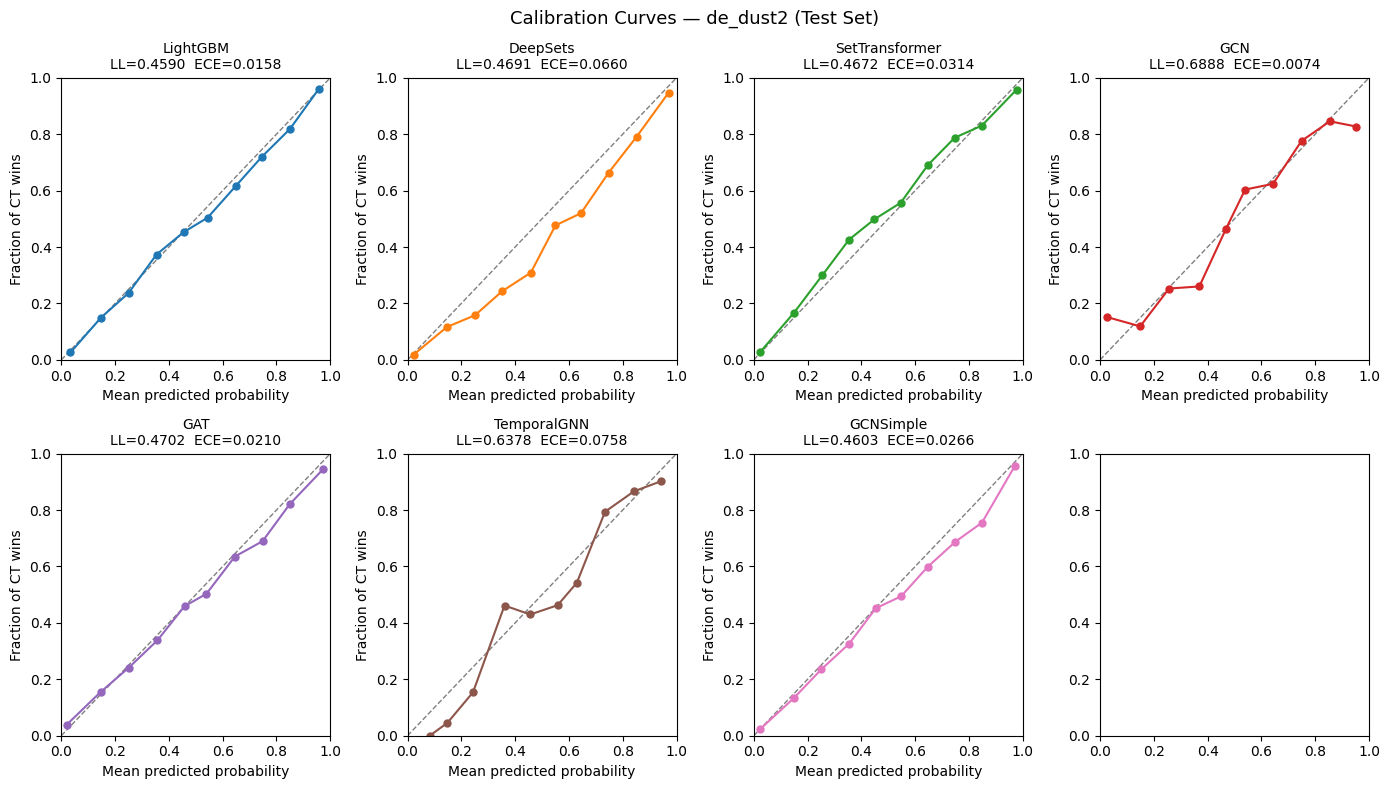

In [41]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

MODEL_NAMES = ['LightGBM', 'DeepSets', 'SetTransformer', 'GCN', 'GAT', 'TemporalGNN', "GCNSimple"]
COLORS = dict(zip(MODEL_NAMES, plt.cm.tab10.colors))

def calibration_curve(y_true, y_prob, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1)
    mp, mt = [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        mask = (y_prob >= lo) & (y_prob < hi)
        if mask.sum() > 0:
            mp.append(y_prob[mask].mean())
            mt.append(y_true[mask].mean())
    return np.array(mp), np.array(mt)

# ── Figure 1: Calibration curves ──────────────────────────────────────────
fig, axes = plt.subplots(2, 4, figsize=(14, 8))
for ax, name in zip(axes.flatten(), MODEL_NAMES):
    if name not in test_preds:
        ax.set_visible(False); continue
    yt, yp = test_preds[name]
    mp, mt = calibration_curve(yt, yp)
    ax.plot([0,1], [0,1], 'k--', lw=1, alpha=0.5)
    ax.plot(mp, mt, 'o-', color=COLORS[name], ms=5)
    ax.set_title(f'{name}\nLL={log_loss(yt,yp):.4f}  ECE={compute_ece(yt,yp):.4f}', fontsize=10)
    ax.set_xlabel('Mean predicted probability')
    ax.set_ylabel('Fraction of CT wins')
    ax.set_xlim(0,1); ax.set_ylim(0,1)

plt.suptitle('Calibration Curves — de_dust2 (Test Set)', fontsize=13)
plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / 'fig_calibration.png', dpi=150, bbox_inches='tight')
plt.show()

### Time-binned Log Loss

In [42]:
# ── Build time index for the test set ─────────────────────────────────────
# Each entry: (seconds_since_phase_start, bomb_planted, y_true)
# Ordering matches the flat iteration order used by flatten_to_states.

time_index = []   # list of (t, bomb_planted)
for match in test_data.values():
    for df_row, label in zip(match['df'], match['Y']):
        time_index.append((
            float(df_row.get('secondsSincePhaseStart', 0)),
            int(df_row.get('bombPlanted', 0)),
        ))

time_arr        = np.array([t for t, _ in time_index])
bomb_arr        = np.array([b for _, b in time_index])
print(f'Time index entries: {len(time_index):,}')
print(f'  secondsSincePhaseStart range: {time_arr.min():.0f} – {time_arr.max():.0f} s')
print(f'  Post-plant states: {bomb_arr.sum():,} ({100*bomb_arr.mean():.1f}%)')

Time index entries: 81,544
  secondsSincePhaseStart range: 0 – 188 s
  Post-plant states: 12,883 (15.8%)


In [43]:
# ── Sanity check: length alignment ────────────────────────────────────────
# The time index must have exactly as many entries as each model's predictions.
# LightGBM's y_test is the reference (df-based, same ordering).
ref_len = len(test_preds['LightGBM'][0])
print(f'LightGBM predictions: {ref_len:,}')
print(f'Time index length:    {len(time_index):,}')
assert len(time_index) == ref_len, (
    f'Mismatch! time_index={len(time_index)}, predictions={ref_len}.\n'
    'This happens if set/graph datasets drop states that df keeps.\n'
    'Use LightGBM predictions only for time-binned analysis, '
    'or rebuild time_index from the set/graph ordering.'
)
print('Length check passed.')

LightGBM predictions: 81,544
Time index length:    81,544
Length check passed.


  Skipping TemporalGNN (length mismatch: 703 vs 81544)


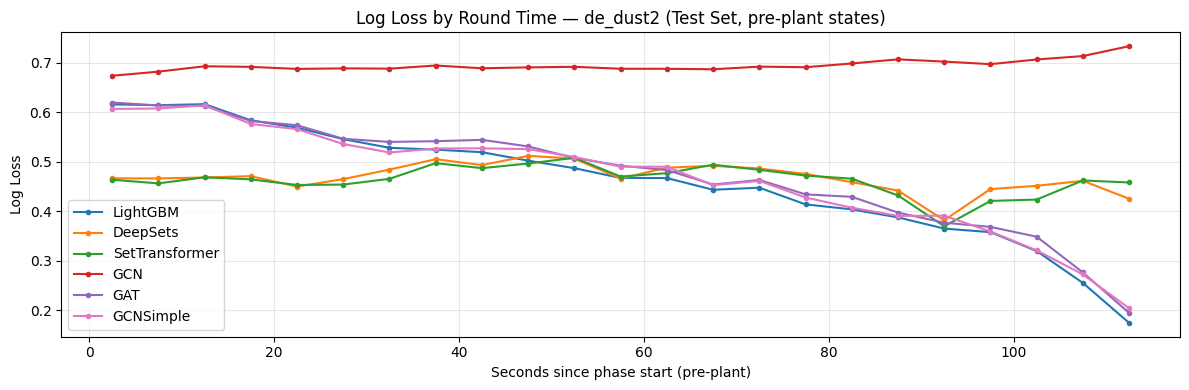

In [44]:
# ── Time-binned Log Loss (replicates ESTA Fig. 6) ─────────────────────────
# Note: secondsSincePhaseStart resets to 0 at bomb plant (ESTA convention),
# so post-plant states start from 0 again.  We analyse pre-plant only here
# to get a clean 0–115s x-axis.  Post-plant analysis follows separately.

BIN_WIDTH = 5   # seconds per bin
MAX_TIME  = 115 # freeze time is 15s, round is 115s buy + action

pre_plant_mask = (bomb_arr == 0)
bin_edges = np.arange(0, MAX_TIME + BIN_WIDTH, BIN_WIDTH)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

fig, ax = plt.subplots(figsize=(12, 4))

for name in MODEL_NAMES:
    if name not in test_preds:
        continue
    yt, yp = test_preds[name]
    # align: set/graph models may have same length as LightGBM because
    # preprocessing keeps only alive-player states — check and skip if not
    if len(yt) != len(time_arr):
        print(f'  Skipping {name} (length mismatch: {len(yt)} vs {len(time_arr)})')
        continue

    ll_by_bin = []
    for lo, hi in zip(bin_edges[:-1], bin_edges[1:]):
        mask = pre_plant_mask & (time_arr >= lo) & (time_arr < hi)
        if mask.sum() < 10:   # skip near-empty bins
            ll_by_bin.append(np.nan)
        else:
            ll_by_bin.append(log_loss(yt[mask], yp[mask]))

    ax.plot(bin_centers, ll_by_bin, '-o', ms=3,
            color=COLORS[name], label=name, lw=1.5)

ax.set_xlabel('Seconds since phase start (pre-plant)')
ax.set_ylabel('Log Loss')
ax.set_title('Log Loss by Round Time — de_dust2 (Test Set, pre-plant states)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / 'fig_ll_by_time.png', dpi=150, bbox_inches='tight')
plt.show()

In [45]:
# ── Last-30-seconds Log Loss ───────────────────────────────────────────────
# "Last 30 seconds" = secondsSincePhaseStart >= 85 (pre-plant)
# OR any post-plant state (bomb timer is 40s, so post-plant is inherently
# late in the round).
# We report both separately for clarity.

LATE_THRESHOLD = 85   # seconds — last 30s of the 115s round

late_preplant_mask  = pre_plant_mask & (time_arr >= LATE_THRESHOLD)
postplant_mask      = (bomb_arr == 1)

print(f'Late pre-plant states  (>={LATE_THRESHOLD}s): {late_preplant_mask.sum():,}')
print(f'Post-plant states:                            {postplant_mask.sum():,}')
print()

print(f'{"Model":<16}  {"Late pre-plant LL":>18}  {"Post-plant LL":>14}  {"Full test LL":>13}')
print('-' * 68)

late_results = {}
for name in MODEL_NAMES:
    if name not in test_preds:
        continue
    yt, yp = test_preds[name]
    if len(yt) != len(time_arr):
        print(f'{name:<16}  (length mismatch — skipped)')
        continue

    ll_full  = log_loss(yt, yp)
    ll_late  = log_loss(yt[late_preplant_mask], yp[late_preplant_mask]) \
               if late_preplant_mask.sum() >= 10 else float('nan')
    ll_plant = log_loss(yt[postplant_mask], yp[postplant_mask]) \
               if postplant_mask.sum() >= 10 else float('nan')

    late_results[name] = {'ll_full': ll_full, 'll_late': ll_late, 'll_plant': ll_plant}
    print(f'{name:<16}  {ll_late:>18.4f}  {ll_plant:>14.4f}  {ll_full:>13.4f}')

Late pre-plant states  (>=85s): 7,934
Post-plant states:                            12,883

Model              Late pre-plant LL   Post-plant LL   Full test LL
--------------------------------------------------------------------
LightGBM                      0.3444          0.2303         0.4590
DeepSets                      0.4296          0.4425         0.4691
SetTransformer                0.4170          0.4615         0.4672
GCN                           0.7061          0.6755         0.6888
GAT                           0.3594          0.2347         0.4702
TemporalGNN       (length mismatch — skipped)
GCNSimple                     0.3554          0.2092         0.4603


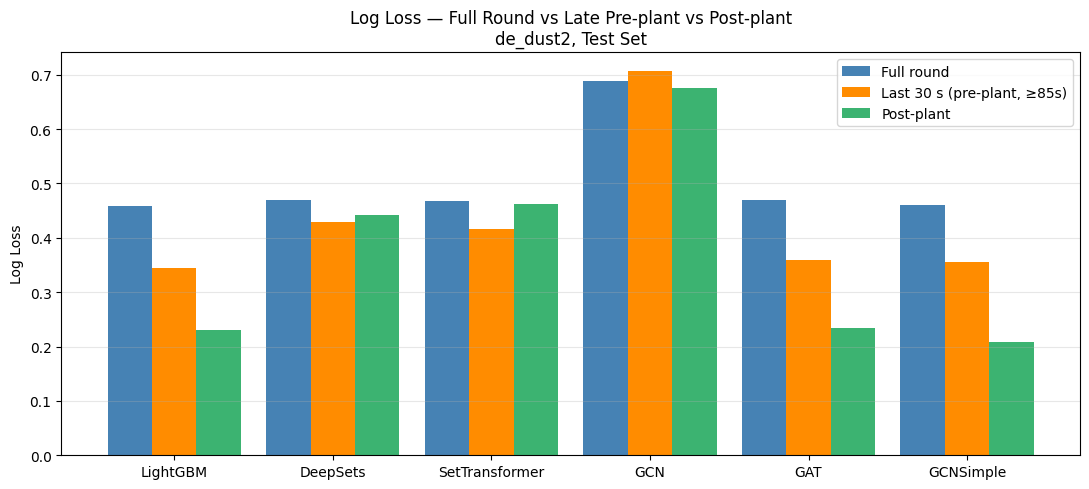

In [46]:
# ── Figure: Late-round LL comparison (bar chart) ──────────────────────────
models_with_data = [n for n in MODEL_NAMES if n in late_results
                    and len(test_preds[n][0]) == len(time_arr)]

x = np.arange(len(models_with_data))
w = 0.28

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(x - w,   [late_results[n]['ll_full']  for n in models_with_data],
       width=w, label='Full round', color='steelblue')
ax.bar(x,       [late_results[n]['ll_late']  for n in models_with_data],
       width=w, label=f'Last 30 s (pre-plant, ≥{LATE_THRESHOLD}s)', color='darkorange')
ax.bar(x + w,   [late_results[n]['ll_plant'] for n in models_with_data],
       width=w, label='Post-plant', color='mediumseagreen')

ax.set_xticks(x)
ax.set_xticklabels(models_with_data)
ax.set_ylabel('Log Loss')
ax.set_title('Log Loss — Full Round vs Late Pre-plant vs Post-plant\nde_dust2, Test Set')
ax.legend()
ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / 'fig_ll_late_round.png', dpi=150, bbox_inches='tight')
plt.show()

In [16]:
from torch.utils.data import Dataset, DataLoader as TorchDataLoader

class TemporalGraphDatasetWithTime(Dataset):
    """
    Same as TemporalGraphDataset but each sample also stores:
      - times : list of secondsSincePhaseStart per state (float)
      - bomb  : list of bombPlanted flags per state (int 0/1)

    This allows post-hoc time-binned evaluation of the Temporal GNN
    without rerunning the full inference pipeline.
    """

    def __init__(self, data: dict, max_len: int = 60):
        self.sequences = []
        self.max_len   = max_len

        for match in data.values():
            # Group by round number — same logic as TemporalGraphDataset
            rounds = {}
            for gnn, label, df_row in zip(match['GNN'], match['Y'], match['df']):
                rnd = df_row.get('roundNum', 0)
                rounds.setdefault(rnd, []).append((gnn, label, df_row))

            for rnd, states in rounds.items():
                if not states:
                    continue
                label  = states[-1][1]
                graphs, times, bombs = [], [], []

                for g, _, df_row in states[:max_len]:
                    x          = torch.tensor(g['x'],         dtype=torch.float)
                    edge_index = torch.tensor(g['edge_index'], dtype=torch.long)
                    edge_attr  = torch.tensor(g['edge_attr'],  dtype=torch.float)
                    graphs.append(Data(x=x, edge_index=edge_index, edge_attr=edge_attr))
                    times.append(float(df_row.get('secondsSincePhaseStart', 0)))
                    bombs.append(int(df_row.get('bombPlanted', 0)))

                self.sequences.append((graphs, label, times, bombs))

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, idx):
        return self.sequences[idx]


def temporal_collate_with_time(batch):
    """
    Collate for TemporalGraphDatasetWithTime.
    Returns the standard (timestep_batches, masks, labels) plus
    times_list and bombs_list so we can track timing per step.
    """
    seqs   = [(seq, lbl) for seq, lbl, _, _ in batch]
    times  = [t for _, _, t, _ in batch]   # list of lists
    bombs  = [b for _, _, _, b in batch]   # list of lists

    max_len = max(len(seq) for seq, _ in seqs)
    labels  = torch.tensor([lbl for _, lbl in seqs], dtype=torch.long)

    timestep_batches, masks = [], []
    for t in range(max_len):
        graphs_at_t, mask_at_t = [], []
        for seq, _ in seqs:
            if t < len(seq):
                graphs_at_t.append(seq[t])
                mask_at_t.append(True)
            else:
                mask_at_t.append(False)
        timestep_batches.append(
            Batch.from_data_list(graphs_at_t) if graphs_at_t else None
        )
        masks.append(mask_at_t)

    return timestep_batches, masks, labels, times, bombs


print('Building timed temporal datasets...')
test_temporal_timed = TemporalGraphDatasetWithTime(
    test_data, max_len=CFG['max_seq_len']
)
print(f'  Test rounds: {len(test_temporal_timed)}')

Building timed temporal datasets...
  Test rounds: 703


In [17]:
# ── Per-state inference for Temporal GNN ──────────────────────────────────
# We run the model on each round's sequence and record a prediction at
# EVERY time step by using teacher-forced prefix inference:
# feed the first t states, read the GRU hidden state after step t.
#
# This requires a small modification to how we call TemporalGNN — we
# need predictions at each step, not just the final step.
#
# We add a helper that returns one logit per time step per sequence.

@torch.no_grad()
def predict_temporal_per_step(
    model: TemporalGNN,
    dataset: TemporalGraphDatasetWithTime,
    batch_size: int = 8,
) -> tuple:
    """
    Run Temporal GNN inference and return one prediction per game state.

    Returns:
        all_time  : np.ndarray, shape (N_states,) — secondsSincePhaseStart
        all_bomb  : np.ndarray, shape (N_states,) — bombPlanted flag
        all_true  : np.ndarray, shape (N_states,) — ground truth label
        all_prob  : np.ndarray, shape (N_states,) — predicted CT win prob
    """
    model.eval()
    loader = TorchDataLoader(
        dataset, batch_size=batch_size, shuffle=False,
        collate_fn=temporal_collate_with_time,
    )

    all_time, all_bomb, all_true, all_prob = [], [], [], []
    dev = next(model.parameters()).device

    for ts_batches, masks, labels, times_batch, bombs_batch in loader:
        B = labels.size(0)
        T = len(ts_batches)
        H = model.gru.hidden_size

        # Build (B, T, H) graph embedding tensor — same as TemporalGNN.forward
        seq = torch.zeros(B, T, H, device=dev)

        graph_embs = []
        for t, g_batch in enumerate(ts_batches):
            if g_batch is not None:
                g_batch = g_batch.to(dev)
                graph_embs.append(model.encode_graph(g_batch))
            else:
                graph_embs.append(None)

        ptr = {t: 0 for t in range(T)}
        for b in range(B):
            for t in range(T):
                if masks[t][b] and graph_embs[t] is not None:
                    seq[b, t] = graph_embs[t][ptr[t]]
                    ptr[t] += 1

        # Run GRU step-by-step, collecting output at each step
        # gru output shape: (B, T, H)
        gru_out, _ = model.gru(seq)   # (B, T, H)

        # For each sequence b, for each valid time step t:
        # predict from gru_out[b, t] and record alongside timing info
        for b in range(B):
            seq_len = len(times_batch[b])  # actual number of states in this round
            label   = labels[b].item()

            for t in range(seq_len):
                logit = model.head(gru_out[b, t])   # (1,)
                prob  = torch.sigmoid(logit).item()
                all_time.append(times_batch[b][t])
                all_bomb.append(bombs_batch[b][t])
                all_true.append(label)
                all_prob.append(prob)

    return (
        np.array(all_time),
        np.array(all_bomb),
        np.array(all_true),
        np.array(all_prob),
    )


print('Running per-step Temporal GNN inference on test set...')
tgnn_time, tgnn_bomb, tgnn_true, tgnn_prob = predict_temporal_per_step(
    temporal_model, test_temporal_timed, batch_size=8
)
print(f'  Per-state predictions: {len(tgnn_true):,}')
print(f'  Overall LL:  {log_loss(tgnn_true, tgnn_prob):.4f}')
print(f'  Overall ECE: {compute_ece(tgnn_true, tgnn_prob):.4f}')

Running per-step Temporal GNN inference on test set...
  Per-state predictions: 74,201
  Overall LL:  0.6637
  Overall ECE: 0.0224


In [18]:
# ── Late-round LL for Temporal GNN ────────────────────────────────────────
LATE_THRESHOLD = 85

pre_plant  = tgnn_bomb == 0
late_mask  = pre_plant & (tgnn_time >= LATE_THRESHOLD)
plant_mask = tgnn_bomb == 1

ll_full  = log_loss(tgnn_true, tgnn_prob)
ll_late  = log_loss(tgnn_true[late_mask],  tgnn_prob[late_mask])  \
           if late_mask.sum() >= 10 else float('nan')
ll_plant = log_loss(tgnn_true[plant_mask], tgnn_prob[plant_mask]) \
           if plant_mask.sum() >= 10 else float('nan')

print('=== TemporalGNN late-round results ===')
print(f'  Full test LL:             {ll_full:.4f}')
print(f'  Late pre-plant (>=85s) LL:{ll_late:.4f}')
print(f'  Post-plant LL:            {ll_plant:.4f}')

=== TemporalGNN late-round results ===
  Full test LL:             0.6637
  Late pre-plant (>=85s) LL:0.6476
  Post-plant LL:            0.6791


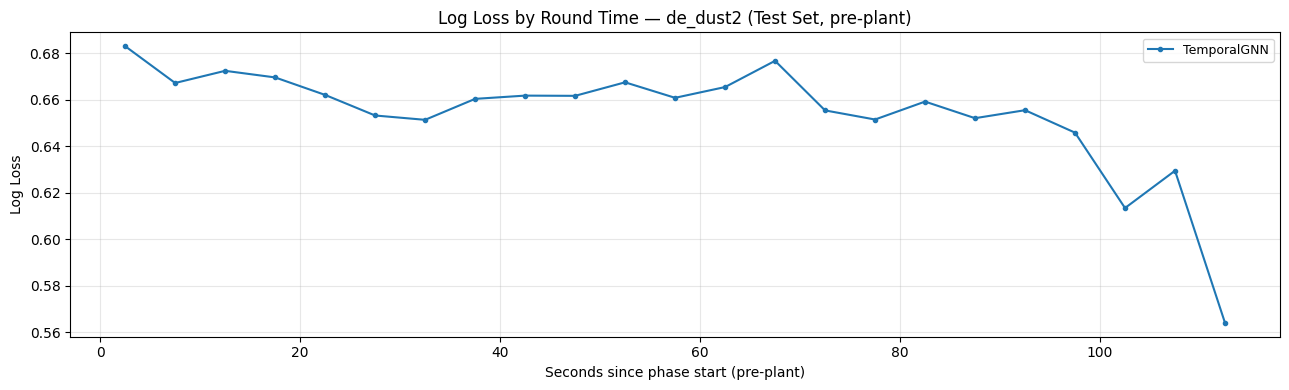

In [20]:
# ── Time-binned LL plot including TemporalGNN ──────────────────────────────
import matplotlib.pyplot as plt

BIN_WIDTH = 5
MAX_TIME  = 115
bin_edges   = np.arange(0, MAX_TIME + BIN_WIDTH, BIN_WIDTH)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

# Re-use test_preds dict from the visualization notebook
# (assumes LightGBM, DeepSets, SetTransformer, GCN, GAT predictions
#  and time_arr / bomb_arr are already in scope)

fig, ax = plt.subplots(figsize=(13, 4))

MODEL_COLORS = dict(zip(
    ['TemporalGNN'],
    plt.cm.tab10.colors
))

# Other models (already aligned with time_arr)
# pre_plant_global = (bomb_arr == 0)
# for name in ['LightGBM', 'DeepSets', 'SetTransformer', 'GCNSimple', 'GAT']:
#     if name not in test_preds:
#         continue
#     yt, yp = test_preds[name]
#     ll_by_bin = []
#     for lo, hi in zip(bin_edges[:-1], bin_edges[1:]):
#         mask = pre_plant_global & (time_arr >= lo) & (time_arr < hi)
#         ll_by_bin.append(
#             log_loss(yt[mask], yp[mask]) if mask.sum() >= 10 else np.nan
#         )
#     ax.plot(bin_centers, ll_by_bin, '-o', ms=3, lw=1.5,
#             color=MODEL_COLORS.get(name, 'gray'), label=name)

# TemporalGNN — uses its own time/bomb arrays
pre_plant_tgnn = (tgnn_bomb == 0)
tgnn_ll_by_bin = []
for lo, hi in zip(bin_edges[:-1], bin_edges[1:]):
    mask = pre_plant_tgnn & (tgnn_time >= lo) & (tgnn_time < hi)
    tgnn_ll_by_bin.append(
        log_loss(tgnn_true[mask], tgnn_prob[mask]) if mask.sum() >= 10 else np.nan
    )
ax.plot(bin_centers, tgnn_ll_by_bin, '-o', ms=3, lw=1.5,
        color=MODEL_COLORS['TemporalGNN'], label='TemporalGNN')

ax.set_xlabel('Seconds since phase start (pre-plant)')
ax.set_ylabel('Log Loss')
ax.set_title('Log Loss by Round Time — de_dust2 (Test Set, pre-plant)')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / 'fig_ll_by_time_v2.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Notes for Thesis

### What to report
- **Primary metrics**: Log Loss (LL) and ECE (10 equal-width bins) on the test split, averaged across 3 independent runs with different random seeds.
- **Baselines to include in Table**: Constant CT predictor (`LL = ln(2) ≈ 0.693`, `ECE = |CT_win_rate − 0.5|`), health-difference logistic regression.
- **Statistical significance**: consider bootstrapped 95% CI on test LL (resample rounds, not states, to respect within-round correlation).

### Architecture decisions to justify
- **Set batching by alive count**: avoids zero-padding which would corrupt the mean aggregation in DeepSets and distort attention in SetTransformer.
- **NNConv vs GATConv**: NNConv uses edge features to *parameterize* the weight matrix per edge; GATConv uses them in the *attention score*. Both are tested.
- **GRU over state sequence** (Temporal GNN): simpler than Transformer for sequences of up to ~60 states; avoids positional encoding issues with variable-length rounds.
- **Chronological split**: prevents data leakage — tactical meta evolves over the tournament calendar.

### Reproducibility checklist
- Seed fixed for Python, NumPy, PyTorch
- Normaliser fitted on train set only, saved to `checkpoints/dust2/normaliser.npz`
- Model checkpoints saved on best validation LL
- Results CSV at `checkpoints/dust2/results_dust2.csv`